<a href="https://colab.research.google.com/github/sakshichaudhari30/Machine-Learning-1633/blob/main/K_means_Cluster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### K Means Clustering

In [1]:
path  = r"https://raw.githubusercontent.com/sakshichaudhari30/Datasets/refs/heads/main/Mall_Customers.csv"
import pandas as pd
df = pd.read_csv(path)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### Perform Basic Data Quality Checks

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [3]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

### Consider features required for X (Cluster formation)

X: age, income, spending

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [7]:
X.columns = ['Age','Income','Spending']
X.head()

,Age,Income,Spending
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [8]:
num_pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
).set_output(transform='pandas')

num_pipe

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

In [9]:
X_pre = num_pipe.fit_transform(X)
X_pre.head()

,Age,Income,Spending
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


### K Means Cluster

In [10]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters=4)
model.fit(X_pre)

KMeans(n_clusters=4)

In [11]:
clusters4 = model.predict(X_pre)
clusters4

array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 0, 3, 0, 0, 0, 1, 1, 1, 1, 0, 3, 2, 2, 3, 2, 3, 2, 1, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 1, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2], dtype=int32)

### Evalution Metric: Inertia

In [12]:
model.inertia_

205.22514747675913

### Choosing the best cluster with the help of Elbow method

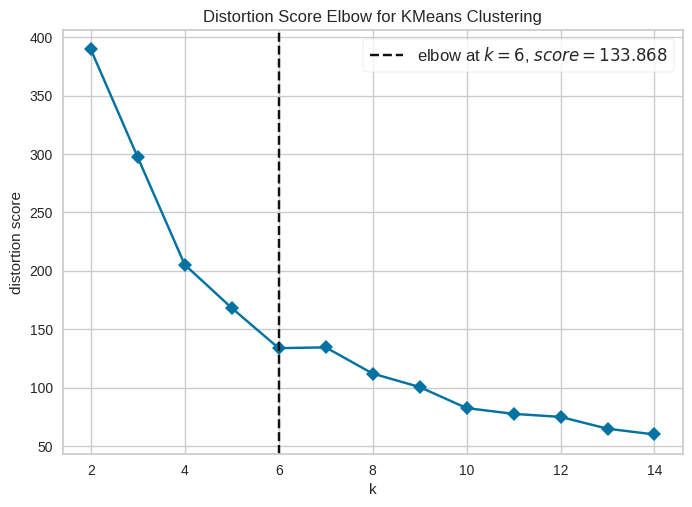

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [13]:
from os import X_OK
from yellowbrick.cluster import kelbow_visualizer
base_model = KMeans()
visualizer = kelbow_visualizer(base_model,X_pre,k = (2,15),timings=False)
visualizer.show()

### The value of k from the eblow method is 6.
### Rebuild the model with number of clusters as 6

In [14]:
final_model = KMeans(n_clusters=6)
final_model.fit(X_pre)


KMeans(n_clusters=6)

In [15]:
labels = final_model.predict(X_pre)
labels

array([3, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3,
       5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 1, 3, 5, 3,
       5, 3, 1, 4, 4, 4, 1, 3, 4, 1, 1, 1, 1, 1, 4, 1, 1, 4, 1, 1, 1, 4,
       1, 1, 4, 4, 1, 1, 1, 1, 1, 4, 1, 4, 4, 1, 1, 4, 1, 1, 4, 1, 1, 4,
       4, 1, 1, 4, 1, 4, 4, 4, 1, 4, 1, 4, 4, 1, 1, 4, 1, 4, 1, 1, 1, 1,
       1, 4, 4, 4, 4, 4, 1, 1, 1, 1, 4, 4, 4, 0, 4, 0, 2, 0, 2, 0, 2, 0,
       4, 0, 4, 0, 2, 0, 4, 0, 2, 0, 4, 0, 4, 0, 2, 0, 2, 0, 2, 0, 2, 0,
       2, 0, 2, 0, 2, 0, 1, 0, 4, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0,
       2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0,
       2, 0], dtype=int32)

### Add this labels list to the Dataframe and share it with the client

In [16]:
df['cluster Number']=labels
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster Number
0,1,Male,19,15,39,3
1,2,Male,21,15,81,3
2,3,Female,20,16,6,5
3,4,Female,23,16,77,3
4,5,Female,31,17,40,5


In [17]:

df[df['Cluster Number']==3]

KeyError: 'Cluster Number'

In [18]:
print("Customer group")
for i in range(5):
  display(df[df['cluster Number']==i])



Customer group


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster Number
123,124,Male,39,69,91,0
125,126,Female,31,70,77,0
127,128,Male,40,71,95,0
129,130,Male,38,71,75,0
131,132,Male,39,71,75,0
133,134,Female,31,72,71,0
135,136,Female,29,73,88,0
137,138,Male,32,73,73,0
139,140,Female,35,74,72,0
141,142,Male,32,75,93,0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster Number
40,41,Female,65,38,35,1
46,47,Female,50,40,55,1
50,51,Female,49,42,52,1
53,54,Male,59,43,60,1
54,55,Female,50,43,45,1
55,56,Male,47,43,41,1
56,57,Female,51,44,50,1
57,58,Male,69,44,46,1
59,60,Male,53,46,46,1
60,61,Male,70,46,56,1


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster Number
126,127,Male,43,71,35,2
128,129,Male,59,71,11,2
130,131,Male,47,71,9,2
136,137,Female,44,73,7,2
140,141,Female,57,75,5,2
146,147,Male,48,77,36,2
148,149,Female,34,78,22,2
150,151,Male,43,78,17,2
152,153,Female,44,78,20,2
154,155,Female,47,78,16,2


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster Number
0,1,Male,19,15,39,3
1,2,Male,21,15,81,3
3,4,Female,23,16,77,3
5,6,Female,22,17,76,3
7,8,Female,23,18,94,3
9,10,Female,30,19,72,3
11,12,Female,35,19,99,3
13,14,Female,24,20,77,3
15,16,Male,22,20,79,3
17,18,Male,20,21,66,3


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster Number
47,48,Female,27,40,47,4
48,49,Female,29,40,42,4
49,50,Female,31,40,42,4
52,53,Female,31,43,54,4
58,59,Female,27,46,51,4
61,62,Male,19,46,55,4
65,66,Male,18,48,59,4
68,69,Male,19,48,59,4
69,70,Female,32,48,47,4
75,76,Male,26,54,54,4
